# 04 – Reduced labels (pilot)

A small first look at the reduced-label setting of the proposal: only **25%** of the multi-label training
images keep their object labels (18 of the 72 training images in every scene, 540 in total). The other 1,620
training images keep only their scene label and are used like the 7,000 scene-only images. Validation and test
images do not change.

This is a pilot with one label fraction. The full reduced-label study (several fractions, with B3) follows
after B3 is built. The questions here are:

- Does scene supervision help more when object labels are scarce (B1 − B0 at 25% vs. at 100%)?
- Does the explicit scene prior of B2 help when there are too few labels to learn the scene–object relation
  (B2 − B1 at 25% vs. at 100%)?

| Run | Description |
|---|---|
| **B0_labels25** | B0 on the 540 labeled images |
| **B0_long_labels25** | B0 trained for 40 epochs, so it sees as many images as B1 |
| **B1_labels25** | B1: 540 labeled images + scene-only images |
| **B2_labels25** | B2: the scene prior P(object \| scene) is computed from the 540 labeled images only |

The labeled subset is fixed, so every model and seed uses the same 540 images.

## 1. Setup

The configuration and seeds are the same as in `02_train_models.ipynb`.

In [1]:
import numpy as np

from aidml import get_device, load_data, plot_history, reduce_labels, run_all, split_indices

device = get_device()
data = load_data()
print("device:", device)

CONFIG = {
    "epochs": 20,
    "batch_size": 32,
    "lr": 1e-4,
    "head_lr": 1e-3,
    "weight_decay": 1e-4,
    "extra_ratio": 1.0,
    "scene_loss_weight": 1.0,
    "pretrained": True,
}
SEEDS = [0, 1, 2]

device: mps


## 2. Check the labeled subset

Number of labeled training images per scene and how often each object appears in them. Labels that become very
rare (for example airplane) are the ones where the scene can help most.

In [2]:
reduced = reduce_labels(data, 0.25)
train_full = split_indices(data, "train")
train_reduced = split_indices(reduced, "train")
print("labeled training images:", len(train_full), "->", len(train_reduced))
print("scene-only images:", len(split_indices(data, "extra")), "->", len(split_indices(reduced, "extra")))
print("validation and test unchanged:",
      all((split_indices(data, s) == split_indices(reduced, s)).all() for s in ["val", "test"]))
print("labeled images per scene:", sorted(set(np.bincount(reduced["scenes"][train_reduced]).tolist())))

counts = data["objects"][train_full].sum(0).astype(int)
counts_reduced = reduced["objects"][train_reduced].sum(0).astype(int)
for name, full, small in sorted(zip(data["object_names"], counts, counts_reduced), key=lambda row: row[2]):
    print(f"{name:10s} {full:5d} -> {small:4d}")

labeled training images: 2160 -> 540
scene-only images: 7000 -> 8620
validation and test unchanged: True
labeled images per scene: [18]
airplane      71 ->   18
tanks         77 ->   19
chaparral     81 ->   23
field        149 ->   35
sea          159 ->   42
sand         186 ->   43
dock         198 ->   47
ship         209 ->   56
court        241 ->   68
water        620 ->  152
bare soil   1057 ->  259
cars        1467 ->  362
buildings   1557 ->  390
pavement    1676 ->  413
grass       1652 ->  415
trees       1725 ->  431


## 3. B0 with 25% of the labels

About 7 minutes per seed.

In [3]:
run_all("B0_labels25", SEEDS, data, CONFIG, device)

--- B0_labels25_seed0 ---


/Users/yagizcetin/Documents/Github/CS415-CourseProject/aidml.py:219: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:212.)
  scenes = torch.from_numpy(data["scenes"])


epoch  1 | object loss 0.4187 | scene loss 0.0000 | val mAP 0.4720 | 30 s
epoch  2 | object loss 0.2735 | scene loss 0.0000 | val mAP 0.6419 | 16 s
epoch  3 | object loss 0.2226 | scene loss 0.0000 | val mAP 0.6961 | 16 s
epoch  4 | object loss 0.1719 | scene loss 0.0000 | val mAP 0.7432 | 16 s
epoch  5 | object loss 0.1474 | scene loss 0.0000 | val mAP 0.7651 | 19 s
epoch  6 | object loss 0.1203 | scene loss 0.0000 | val mAP 0.7947 | 28 s
epoch  7 | object loss 0.0994 | scene loss 0.0000 | val mAP 0.7971 | 32 s
epoch  8 | object loss 0.0795 | scene loss 0.0000 | val mAP 0.8152 | 35 s
epoch  9 | object loss 0.0665 | scene loss 0.0000 | val mAP 0.8205 | 45 s
epoch 10 | object loss 0.0624 | scene loss 0.0000 | val mAP 0.8276 | 40 s
epoch 11 | object loss 0.0554 | scene loss 0.0000 | val mAP 0.8246 | 35 s
epoch 12 | object loss 0.0512 | scene loss 0.0000 | val mAP 0.8287 | 49 s
epoch 13 | object loss 0.0453 | scene loss 0.0000 | val mAP 0.8321 | 41 s
epoch 14 | object loss 0.0375 | scene 

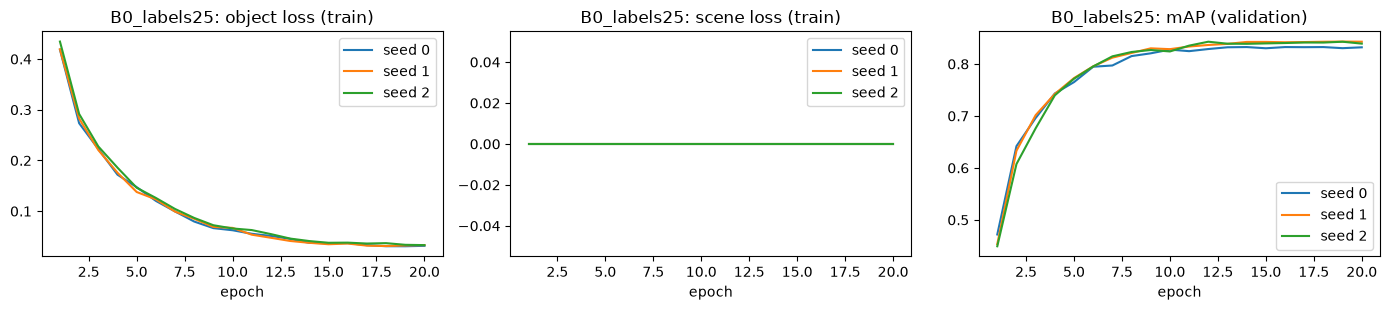

In [4]:
plot_history("B0_labels25")

## 4. B0_long with 25% of the labels

About 14 minutes per seed.

In [5]:
run_all("B0_long_labels25", SEEDS, data, CONFIG, device)

--- B0_long_labels25_seed0 ---
epoch  1 | object loss 0.4187 | scene loss 0.0000 | val mAP 0.4720 | 26 s
epoch  2 | object loss 0.2734 | scene loss 0.0000 | val mAP 0.6429 | 23 s
epoch  3 | object loss 0.2223 | scene loss 0.0000 | val mAP 0.6948 | 21 s
epoch  4 | object loss 0.1711 | scene loss 0.0000 | val mAP 0.7447 | 21 s
epoch  5 | object loss 0.1458 | scene loss 0.0000 | val mAP 0.7718 | 22 s
epoch  6 | object loss 0.1170 | scene loss 0.0000 | val mAP 0.8061 | 26 s
epoch  7 | object loss 0.0950 | scene loss 0.0000 | val mAP 0.8080 | 21 s
epoch  8 | object loss 0.0735 | scene loss 0.0000 | val mAP 0.8216 | 21 s
epoch  9 | object loss 0.0596 | scene loss 0.0000 | val mAP 0.8300 | 22 s
epoch 10 | object loss 0.0555 | scene loss 0.0000 | val mAP 0.8352 | 21 s
epoch 11 | object loss 0.0473 | scene loss 0.0000 | val mAP 0.8368 | 21 s
epoch 12 | object loss 0.0420 | scene loss 0.0000 | val mAP 0.8372 | 22 s
epoch 13 | object loss 0.0347 | scene loss 0.0000 | val mAP 0.8463 | 21 s
epoch 1

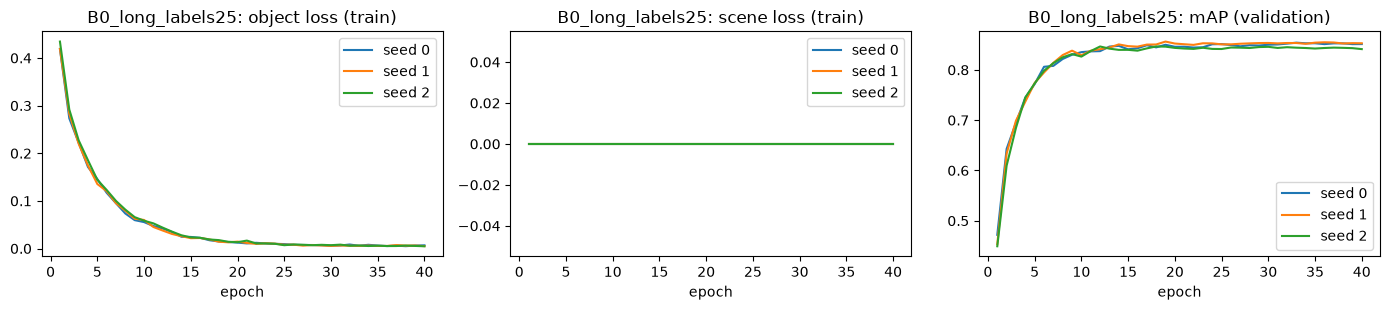

In [6]:
plot_history("B0_long_labels25")

## 5. B1 with 25% of the labels

About 15 minutes per seed.

In [7]:
run_all("B1_labels25", SEEDS, data, CONFIG, device)

--- B1_labels25_seed0 ---
epoch  1 | object loss 0.3923 | scene loss 2.5051 | val mAP 0.5378 | 48 s
epoch  2 | object loss 0.2204 | scene loss 0.8004 | val mAP 0.7674 | 41 s
epoch  3 | object loss 0.1650 | scene loss 0.3666 | val mAP 0.8273 | 42 s
epoch  4 | object loss 0.1358 | scene loss 0.2872 | val mAP 0.8438 | 41 s
epoch  5 | object loss 0.1181 | scene loss 0.2165 | val mAP 0.8567 | 42 s
epoch  6 | object loss 0.1078 | scene loss 0.1707 | val mAP 0.8570 | 38 s
epoch  7 | object loss 0.0948 | scene loss 0.1514 | val mAP 0.8572 | 39 s
epoch  8 | object loss 0.0881 | scene loss 0.1555 | val mAP 0.8644 | 42 s
epoch  9 | object loss 0.0839 | scene loss 0.1389 | val mAP 0.8574 | 36 s
epoch 10 | object loss 0.0784 | scene loss 0.1681 | val mAP 0.8665 | 36 s
epoch 11 | object loss 0.0699 | scene loss 0.1178 | val mAP 0.8673 | 37 s
epoch 12 | object loss 0.0682 | scene loss 0.1065 | val mAP 0.8714 | 37 s
epoch 13 | object loss 0.0666 | scene loss 0.0824 | val mAP 0.8766 | 37 s
epoch 14 | o

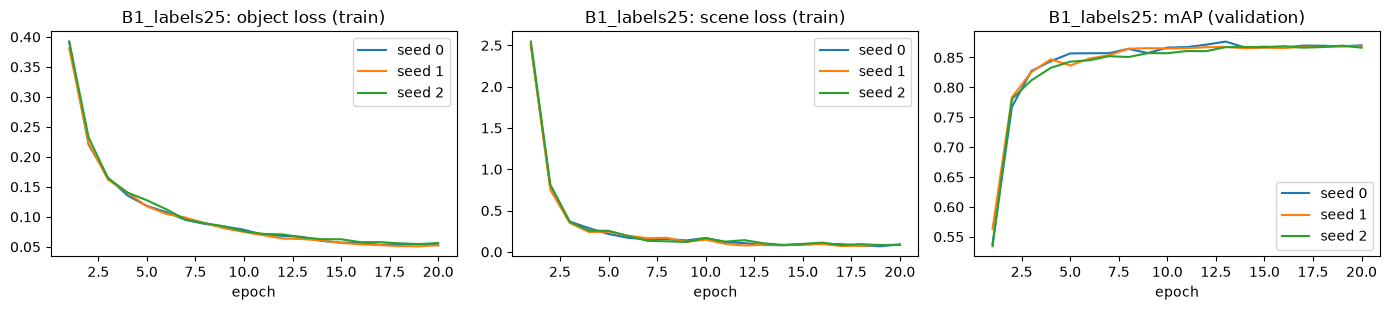

In [8]:
plot_history("B1_labels25")

## 6. B2 with 25% of the labels

About 14 minutes per seed.

In [9]:
run_all("B2_labels25", SEEDS, data, CONFIG, device)

--- B2_labels25_seed0 ---
epoch  1 | object loss 0.3918 | scene loss 2.5034 | val mAP 0.5448 | 39 s
epoch  2 | object loss 0.2181 | scene loss 0.7966 | val mAP 0.7674 | 38 s
epoch  3 | object loss 0.1628 | scene loss 0.3715 | val mAP 0.8234 | 37 s
epoch  4 | object loss 0.1325 | scene loss 0.2766 | val mAP 0.8415 | 36 s
epoch  5 | object loss 0.1156 | scene loss 0.2079 | val mAP 0.8514 | 36 s
epoch  6 | object loss 0.1063 | scene loss 0.1683 | val mAP 0.8575 | 36 s
epoch  7 | object loss 0.0941 | scene loss 0.1568 | val mAP 0.8585 | 36 s
epoch  8 | object loss 0.0868 | scene loss 0.1560 | val mAP 0.8673 | 36 s
epoch  9 | object loss 0.0839 | scene loss 0.1505 | val mAP 0.8582 | 36 s
epoch 10 | object loss 0.0783 | scene loss 0.1716 | val mAP 0.8652 | 37 s
epoch 11 | object loss 0.0698 | scene loss 0.1251 | val mAP 0.8620 | 36 s
epoch 12 | object loss 0.0675 | scene loss 0.1076 | val mAP 0.8720 | 35 s
epoch 13 | object loss 0.0667 | scene loss 0.0835 | val mAP 0.8712 | 36 s
epoch 14 | o

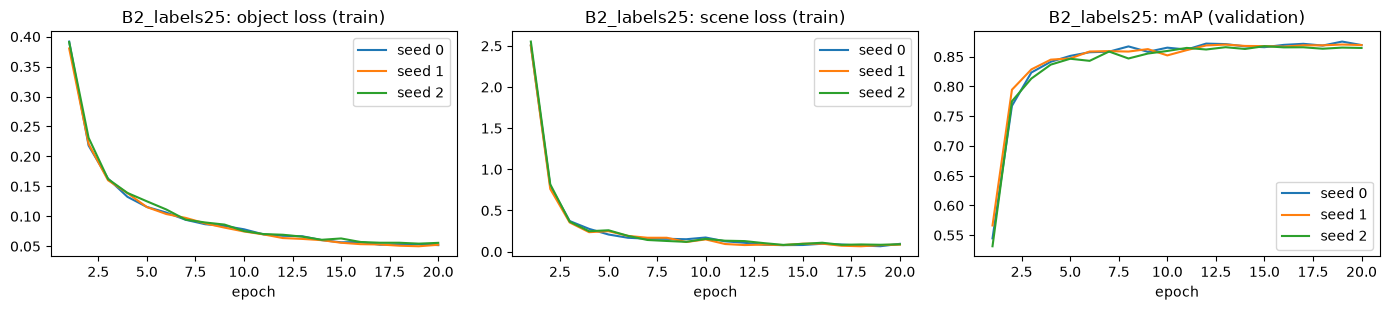

In [10]:
plot_history("B2_labels25")